# 1. Exploratory Data Analysis (EDA)
**APRAU 2026/27 — Group 18**

Sections:
1. Setup & Data Loading
2. Dataset Overview
3. Descriptive Statistics
4. Univariate Analysis
5. Bivariate Analysis

## 1.1 Setup

In [11]:
# Run this cell only on Google Colab
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Adjust path to where you placed the dataset on Drive
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    DATASET_PATH = '../dataset_grupo_18.csv'

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

## 1.2 Data Loading

In [13]:
df = pd.read_csv(DATASET_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Female,Overweight,Never,41,0.448276,26.039307,5.406343,287.000000,8.393934,176.000000,Moderate,No,Medium,No,No,126.000000,Medium,1.656905,5.747705,133.176000,89.793143,15.027543,8.477600,74.022857,64.889143,130.259429,Secondary,Employed,133.176000,9.42,1.111734,128.726611,97.0,N
1,Mature,Female,Normal,Current,47,0.517241,20.800000,6.945000,245.000000,9.800000,60.000000,High,No,Low,No,No,151.462687,Medium,7.000985,12.332504,123.000000,75.000000,8.300000,11.400000,88.000000,67.000000,118.000000,Secondary,Employed,123.000000,9.42,1.162052,129.057613,96.0,DI
2,Senior,Male,Normal,Former,76,0.850574,20.500000,5.362764,218.000000,6.300000,86.000000,Low,No,Low,No,No,149.402373,Medium,7.339123,12.304990,168.000000,79.000000,4.500000,8.700000,84.000000,59.000000,105.000000,Secondary,Unemployed,168.000000,9.42,1.424600,129.050057,169.0,N
3,Young,Female,Overweight,Never,20,0.206897,29.810000,4.800000,225.928571,7.000592,227.250000,High,Yes,High,Yes,Yes,150.785714,Low,7.628842,12.321293,133.642553,89.510638,15.708085,8.439149,73.553191,65.804255,133.378723,Primary,Unemployed,133.642553,9.42,1.063741,164.000000,90.0,N
4,Middle,Male,Overweight,Former,35,0.379310,27.320000,6.000000,225.071183,7.040413,148.762342,Low,No,Medium,No,Yes,147.833988,Low,7.414141,12.534473,134.235362,89.431688,15.107577,8.429047,74.042480,63.850746,130.987371,Secondary,Unemployed,134.235362,9.42,0.952215,130.545353,158.0,N


## 2. Dataset Overview

In [14]:
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Missing Values ===')
print(df.isnull().sum())

=== Data Types ===
age_level                object
gender                   object
bmi_level                object
smoking                  object
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity        object
family_history           object
stress_level             object
low_hdl_cholesterol      object
high_ldl_cholesterol     object
blood_pressure          float64
sugar_consumption        object
crp_level               float64
homocysteine_level      float64
systolic_bp             float64
diastolic_bp            float64
alcohol_intake          float64
salt_intake             float64
heart_rate              float64
hdl                     float64
ldl                     float64
education_level          object
employment_status        object
systolic_index          float64
calcium_baseline     

In [15]:
# Separate feature types
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols   = df.select_dtypes(include=[np.number]).columns.tolist()

print('Categorical:', categorical_cols)
print('Numerical:  ', numerical_cols)

Categorical: ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']
Numerical:   ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']


=== target_class distribution ===
target_class
N     1450
DI     467
HT      83
Name: count, dtype: int64


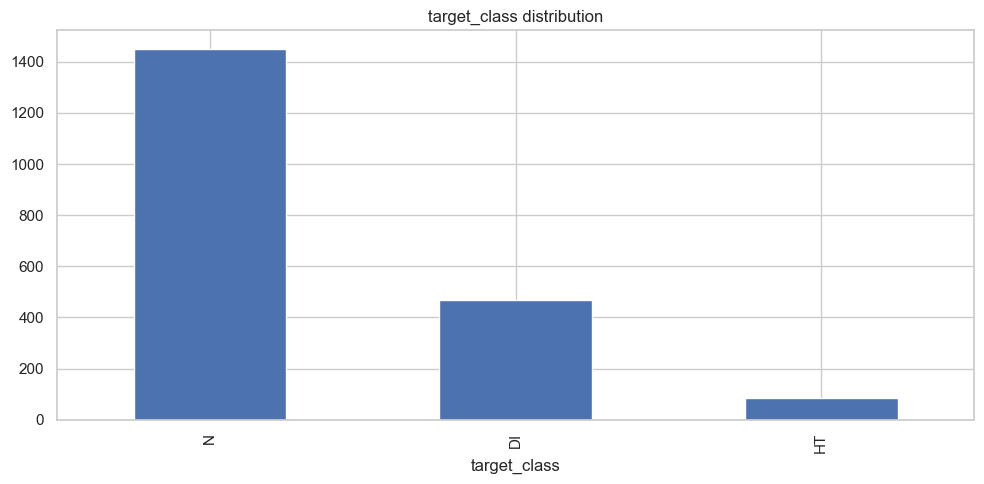

In [16]:
# Class balance
print('=== target_class distribution ===')
print(df['target_class'].value_counts())
df['target_class'].value_counts().plot(kind='bar', title='target_class distribution')
plt.tight_layout()
plt.show()

## 3. Descriptive Statistics

In [17]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age_level,2000,4,Mature,623,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,2000,2,Female,1127,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi_level,2000,4,Overweight,719,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking,2000,3,Never,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2000.0,NaN,NaN,NaN,46.7785,22.18212,2.0,29.0,47.0,65.0,89.0
age_normalized,2000.0,NaN,NaN,NaN,0.514695,0.254967,0.0,0.310345,0.517241,0.724137,1.0
bmi,2000.0,NaN,NaN,NaN,27.097259,6.67574,10.59,22.43,27.32,30.971278,64.27
HbA1c_level,2000.0,NaN,NaN,NaN,5.7123,1.033372,3.5,5.245652,5.7,6.5,9.0
cholesterol,2000.0,NaN,NaN,NaN,223.494228,28.249128,150.0,217.232323,225.0,229.631579,299.0
sleep_hours,2000.0,NaN,NaN,NaN,6.930174,1.154802,4.0,6.770819,6.968389,7.080402,10.0


## 4. Univariate Analysis

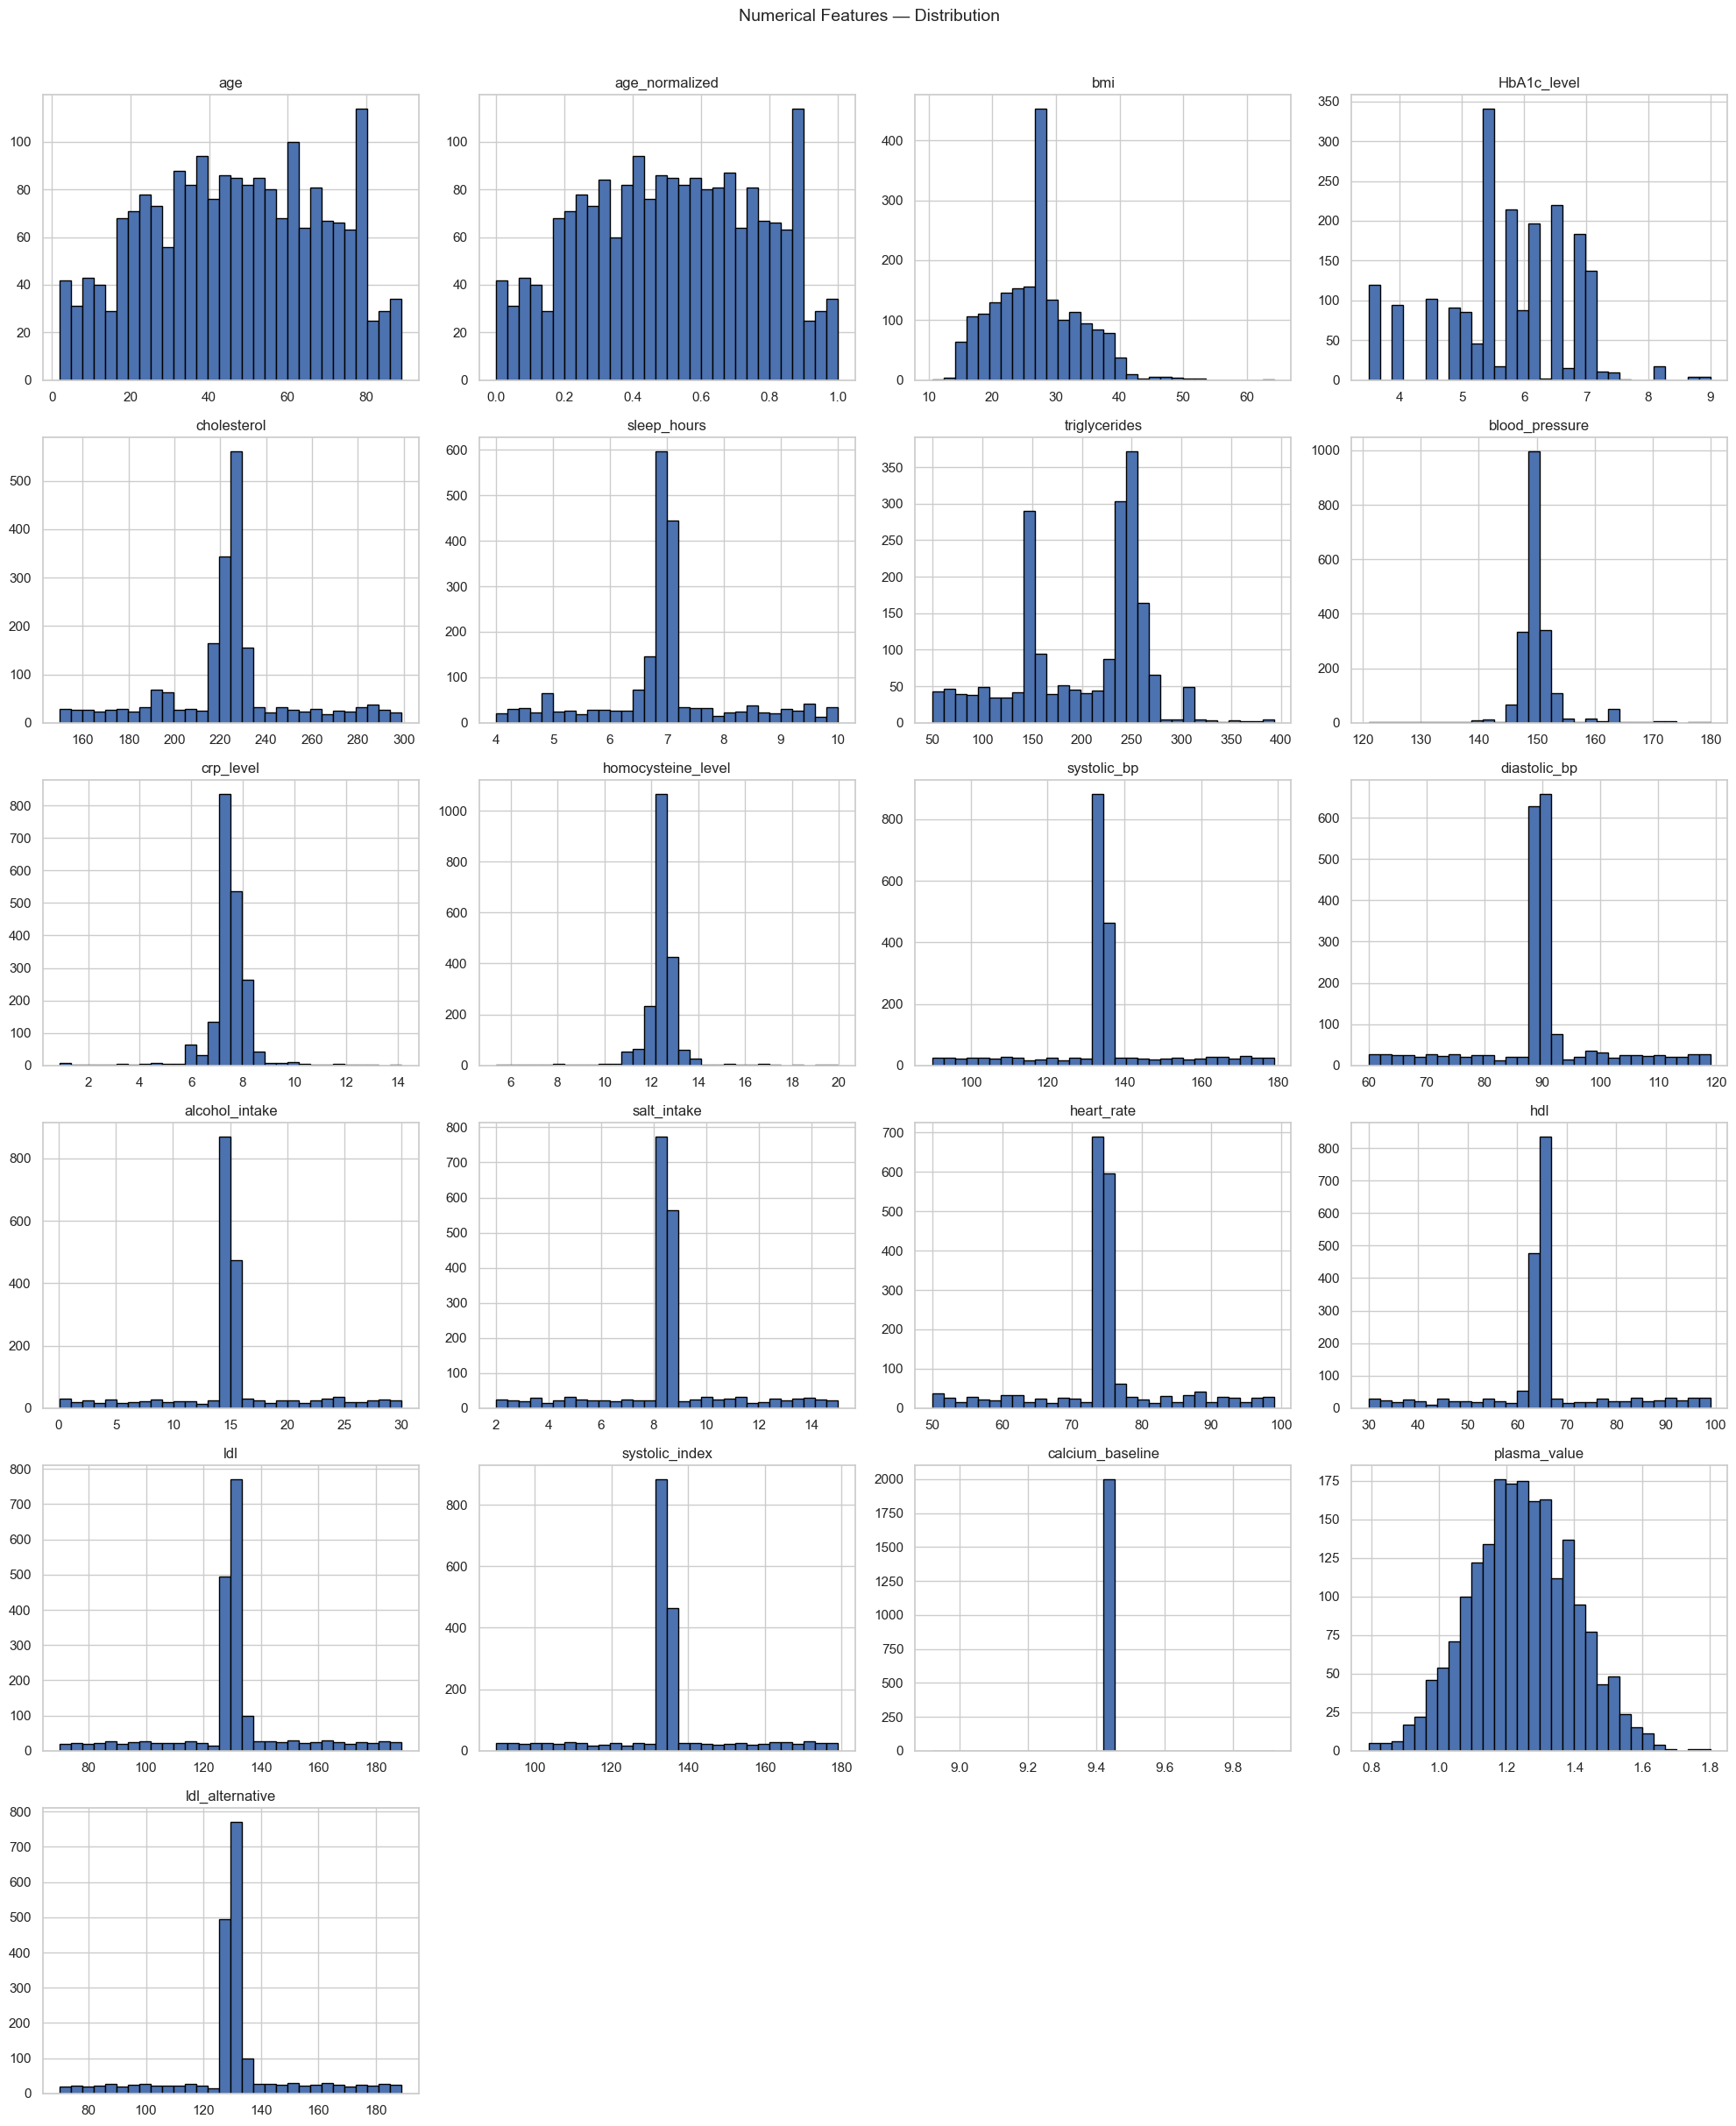

In [18]:
# Histograms for numerical features
num_features = [c for c in numerical_cols if c not in ['target_regression']]
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='black')
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Numerical Features — Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

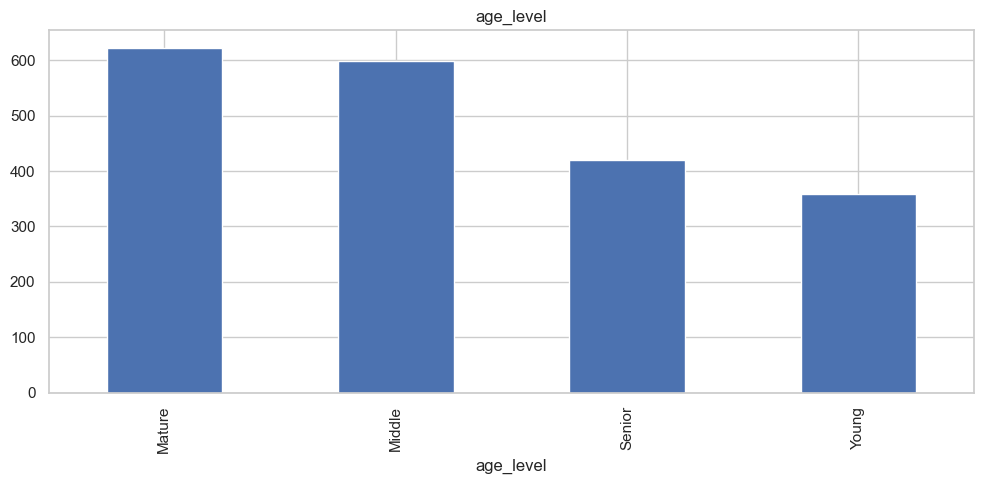

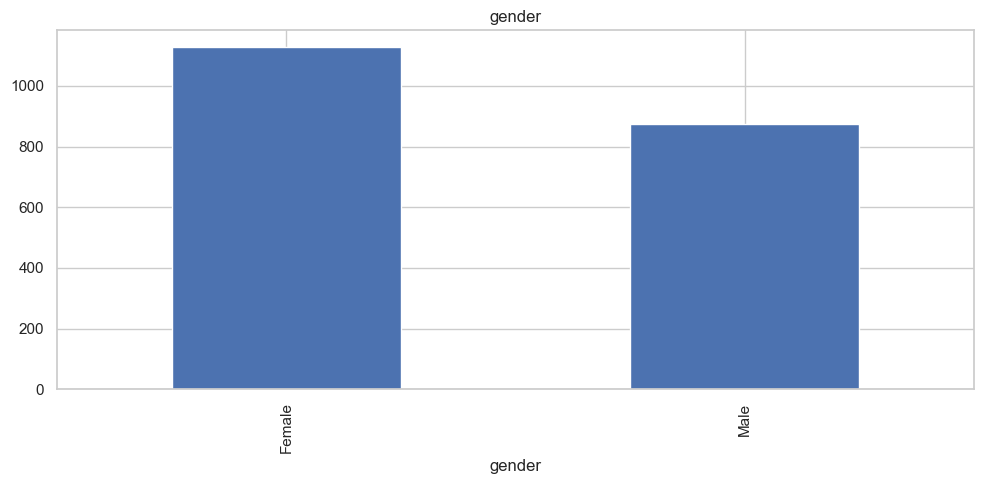

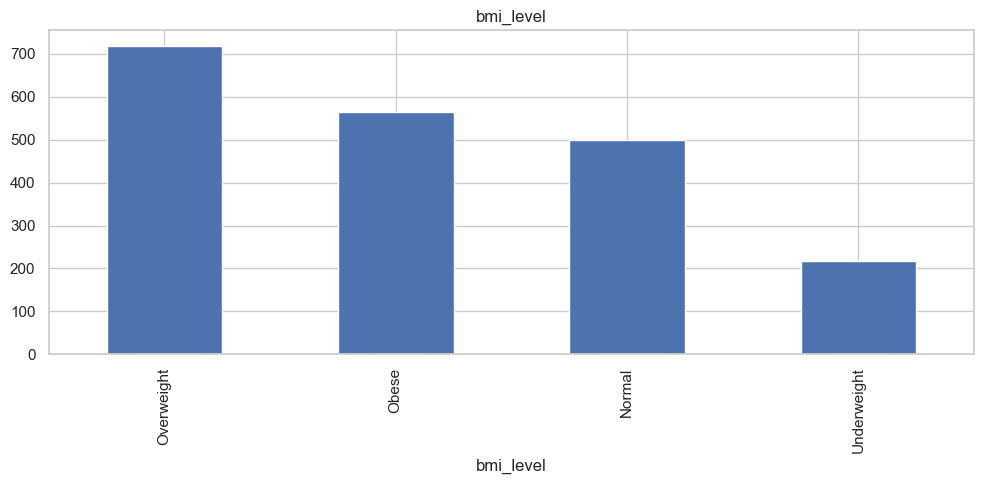

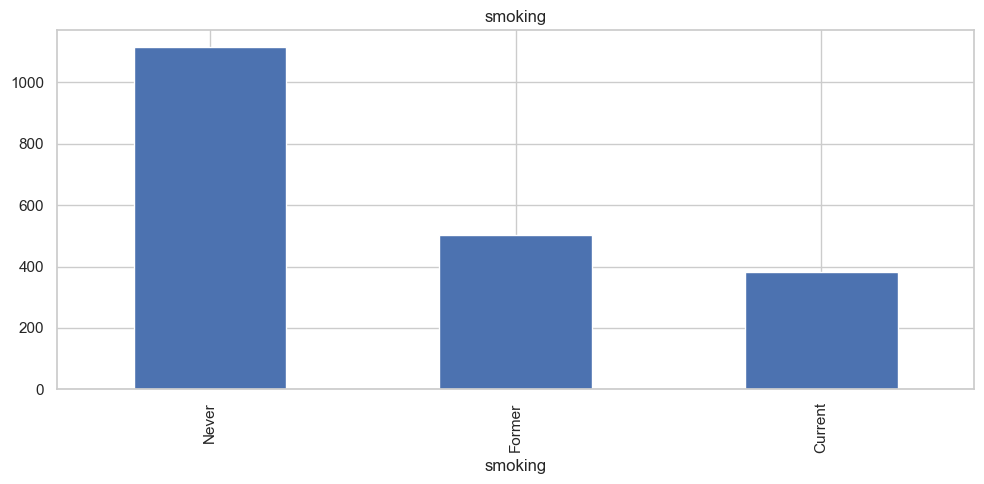

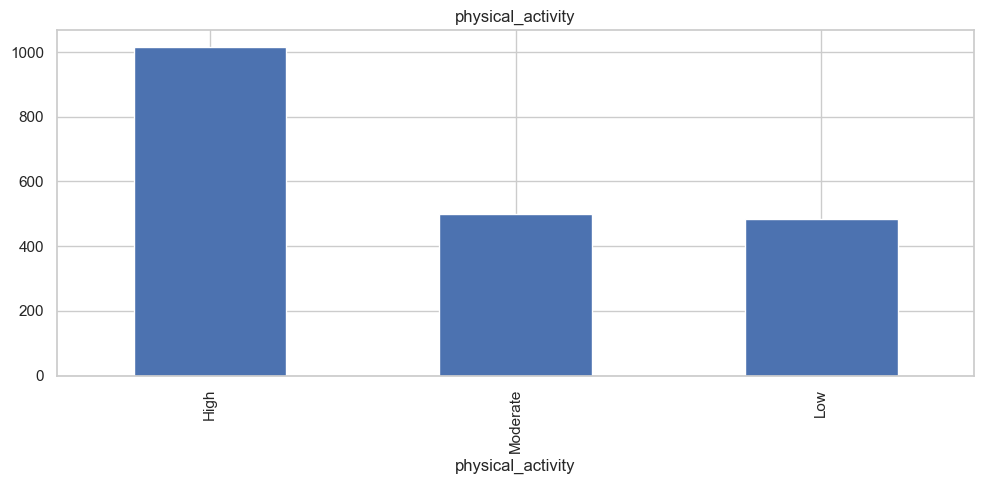

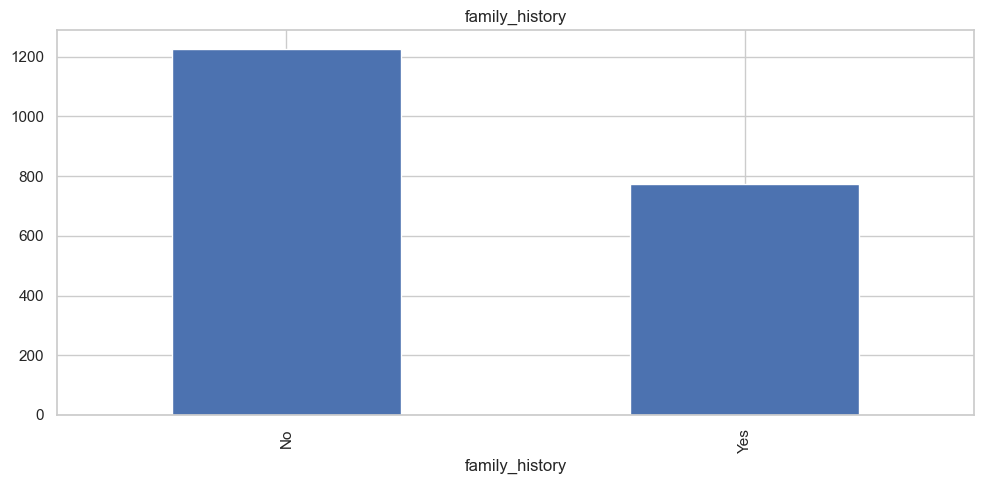

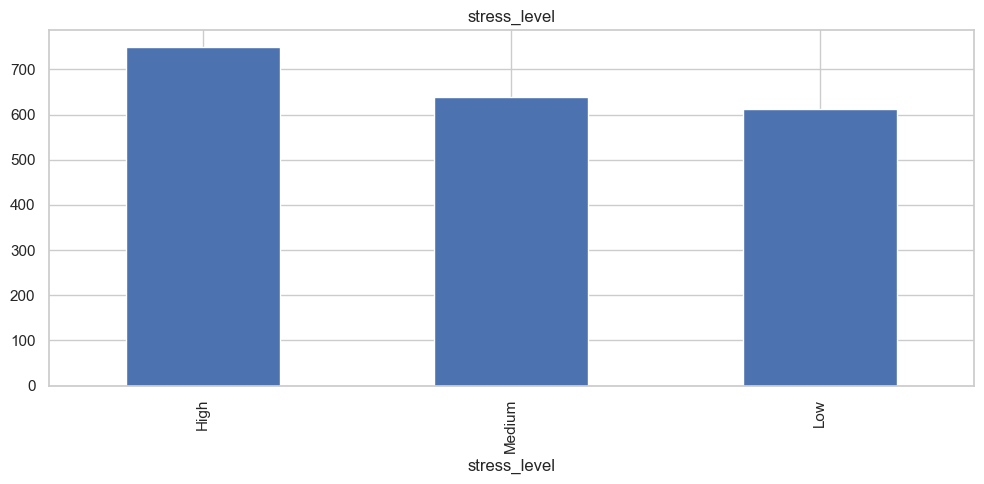

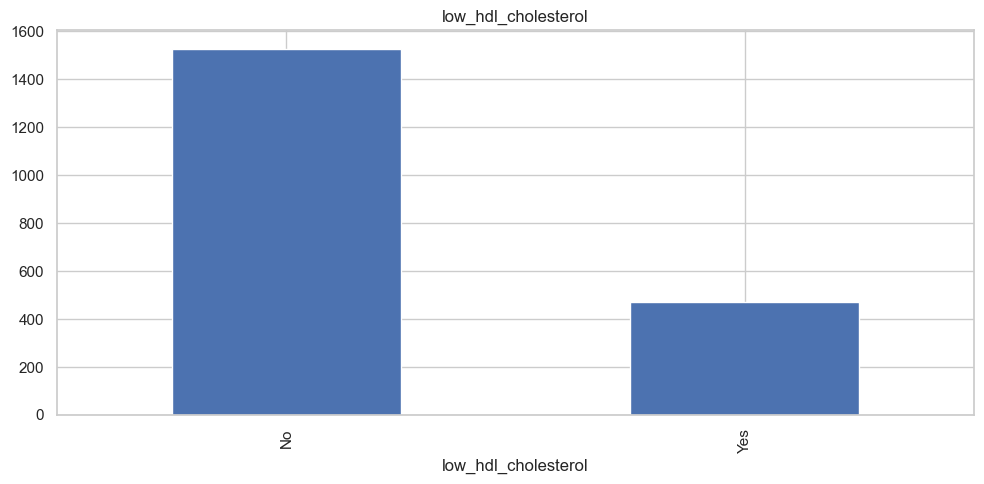

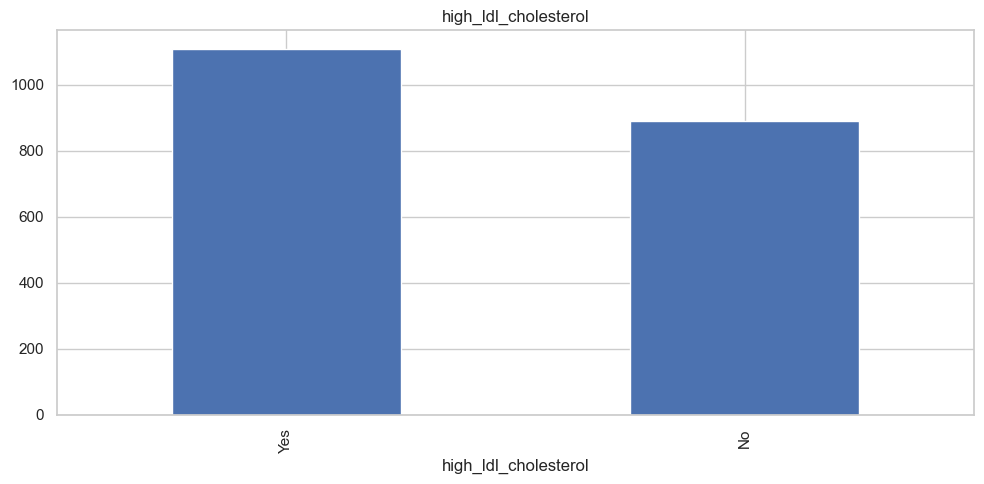

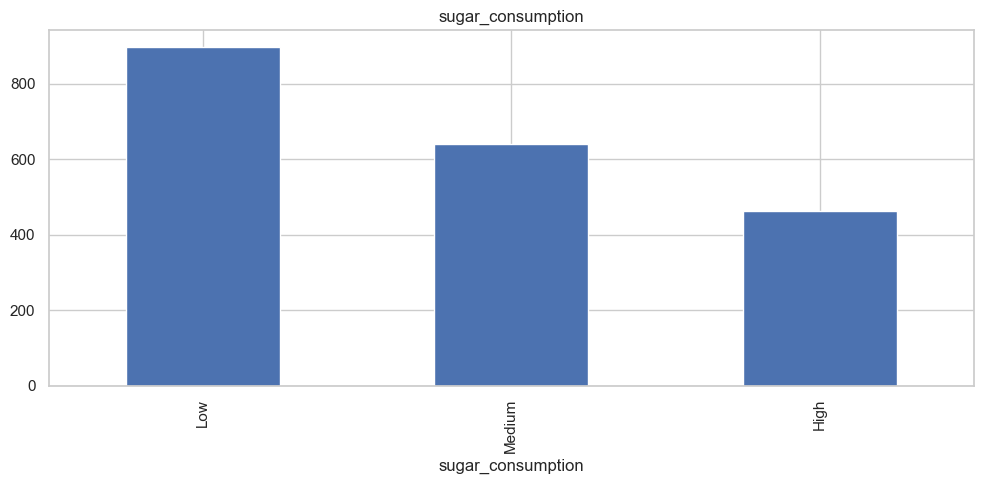

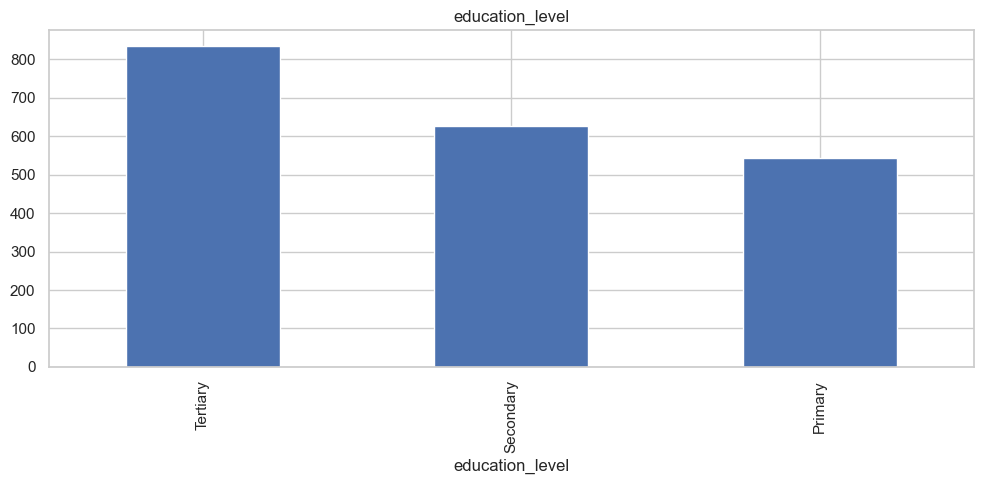

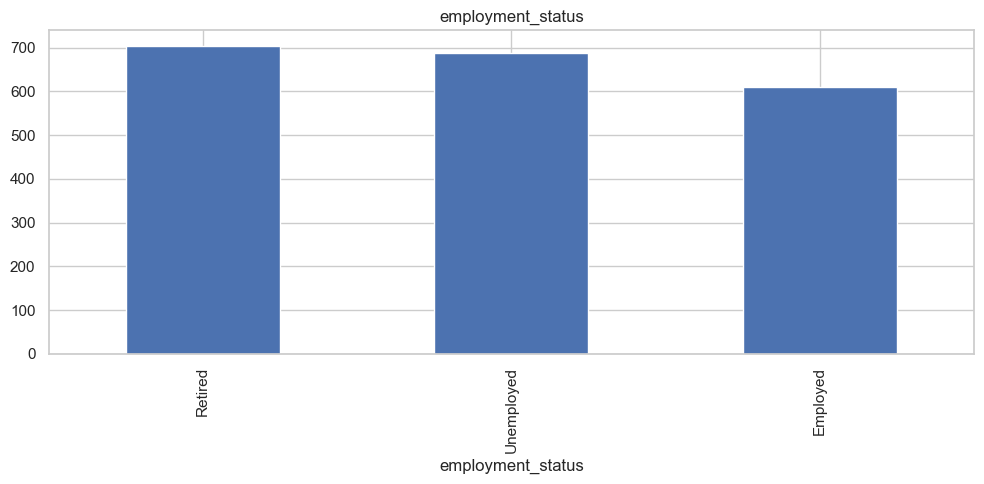

In [19]:
# Bar charts for categorical features
cat_features = [c for c in categorical_cols if c != 'target_class']

for col in cat_features:
    df[col].value_counts().plot(kind='bar', title=col)
    plt.tight_layout()
    plt.show()

## 5. Bivariate Analysis

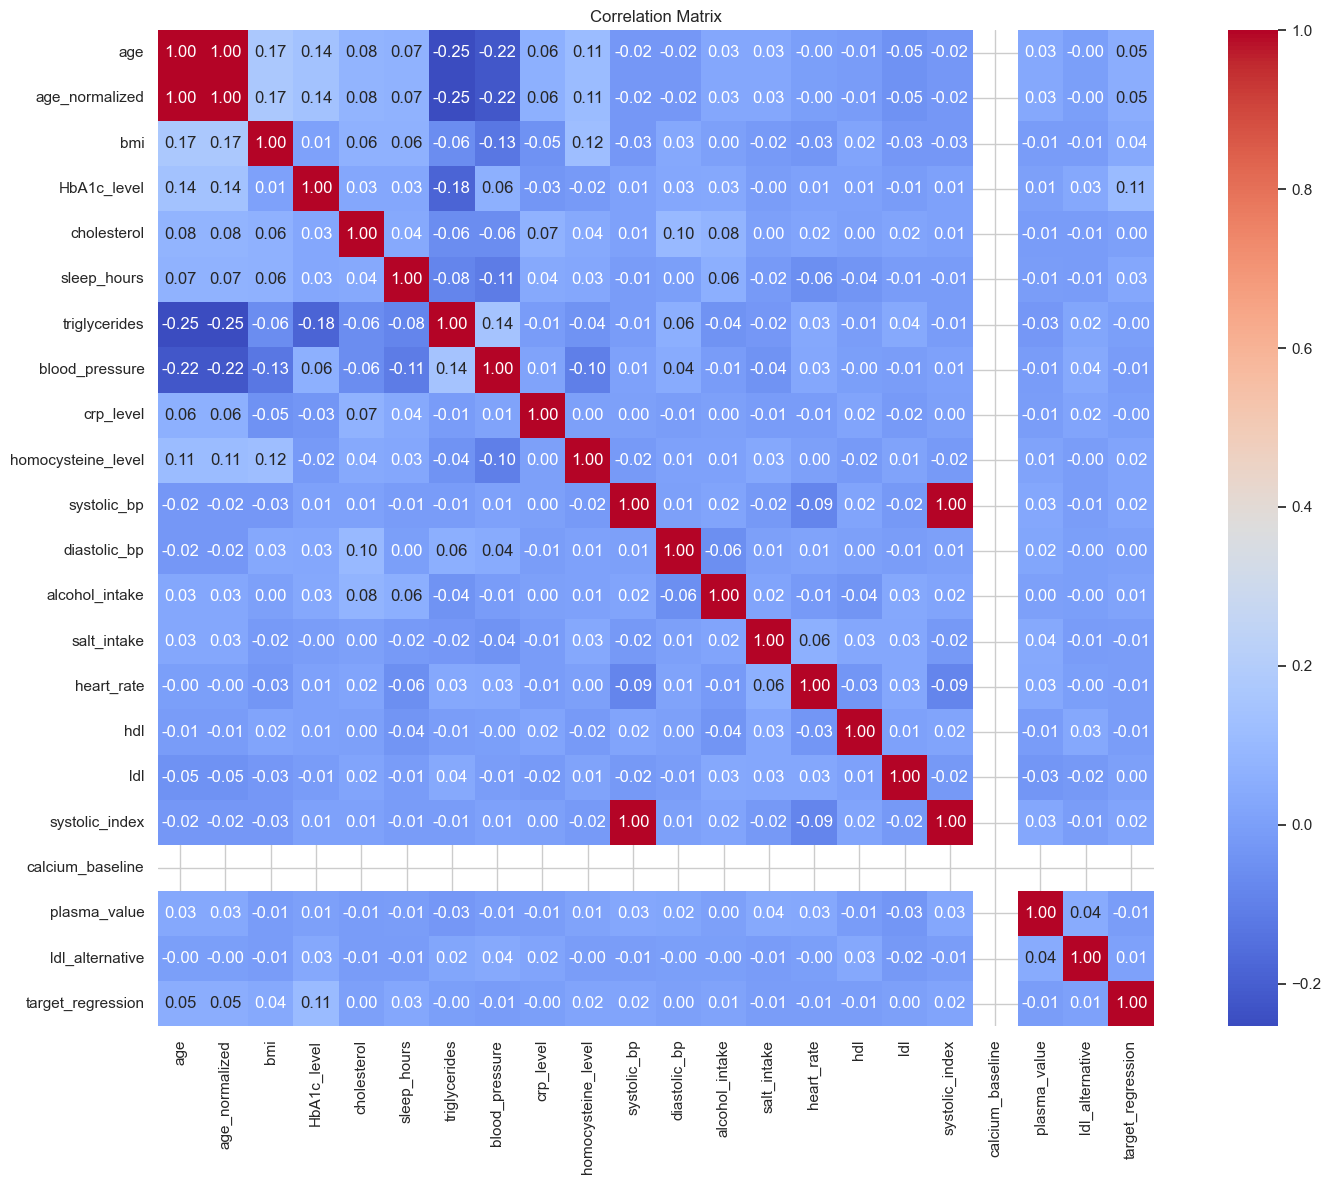

In [20]:
# Correlation heatmap (numerical features)
corr = df[numerical_cols].corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

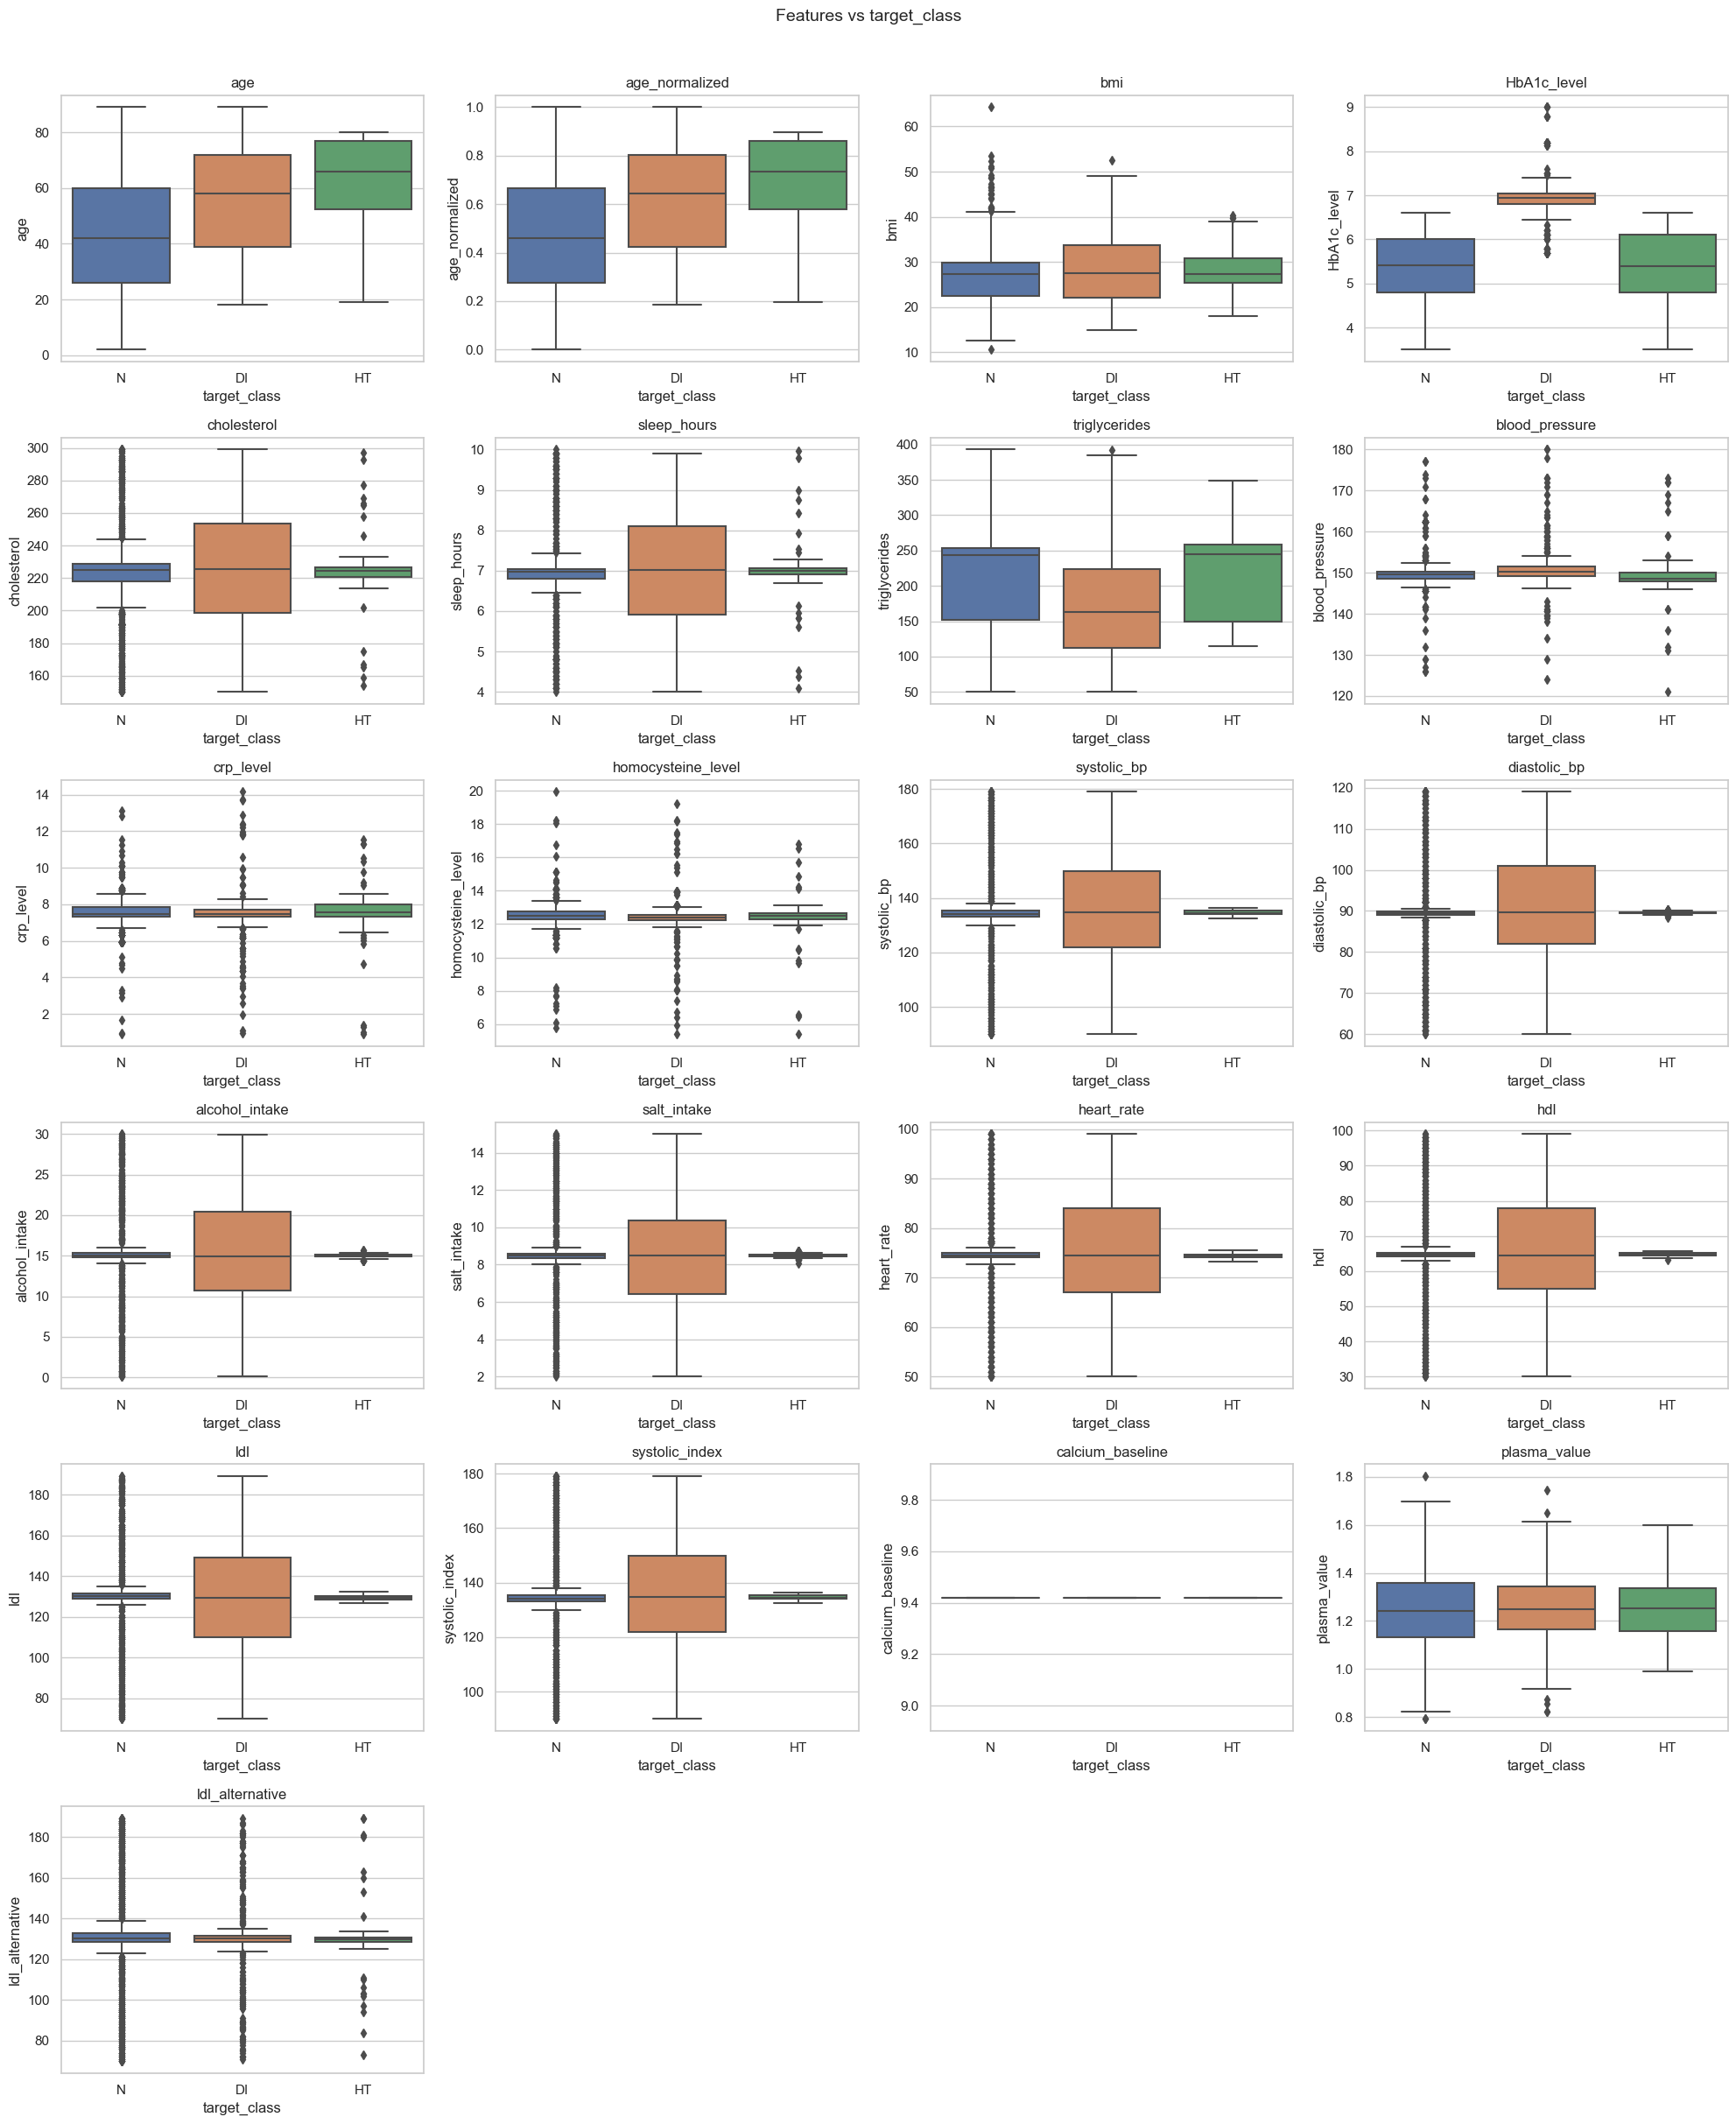

In [21]:
# Boxplots: numerical features vs target_class
n = len(num_features)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(x='target_class', y=col, data=df, ax=axes[i])
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Features vs target_class', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Top correlations with target_regression:
HbA1c_level           0.106513
age_normalized        0.053761
age                   0.053761
bmi                   0.036418
sleep_hours           0.026823
systolic_index        0.018374
systolic_bp           0.018374
homocysteine_level    0.018204
alcohol_intake        0.014946
blood_pressure        0.011194
Name: target_regression, dtype: float64


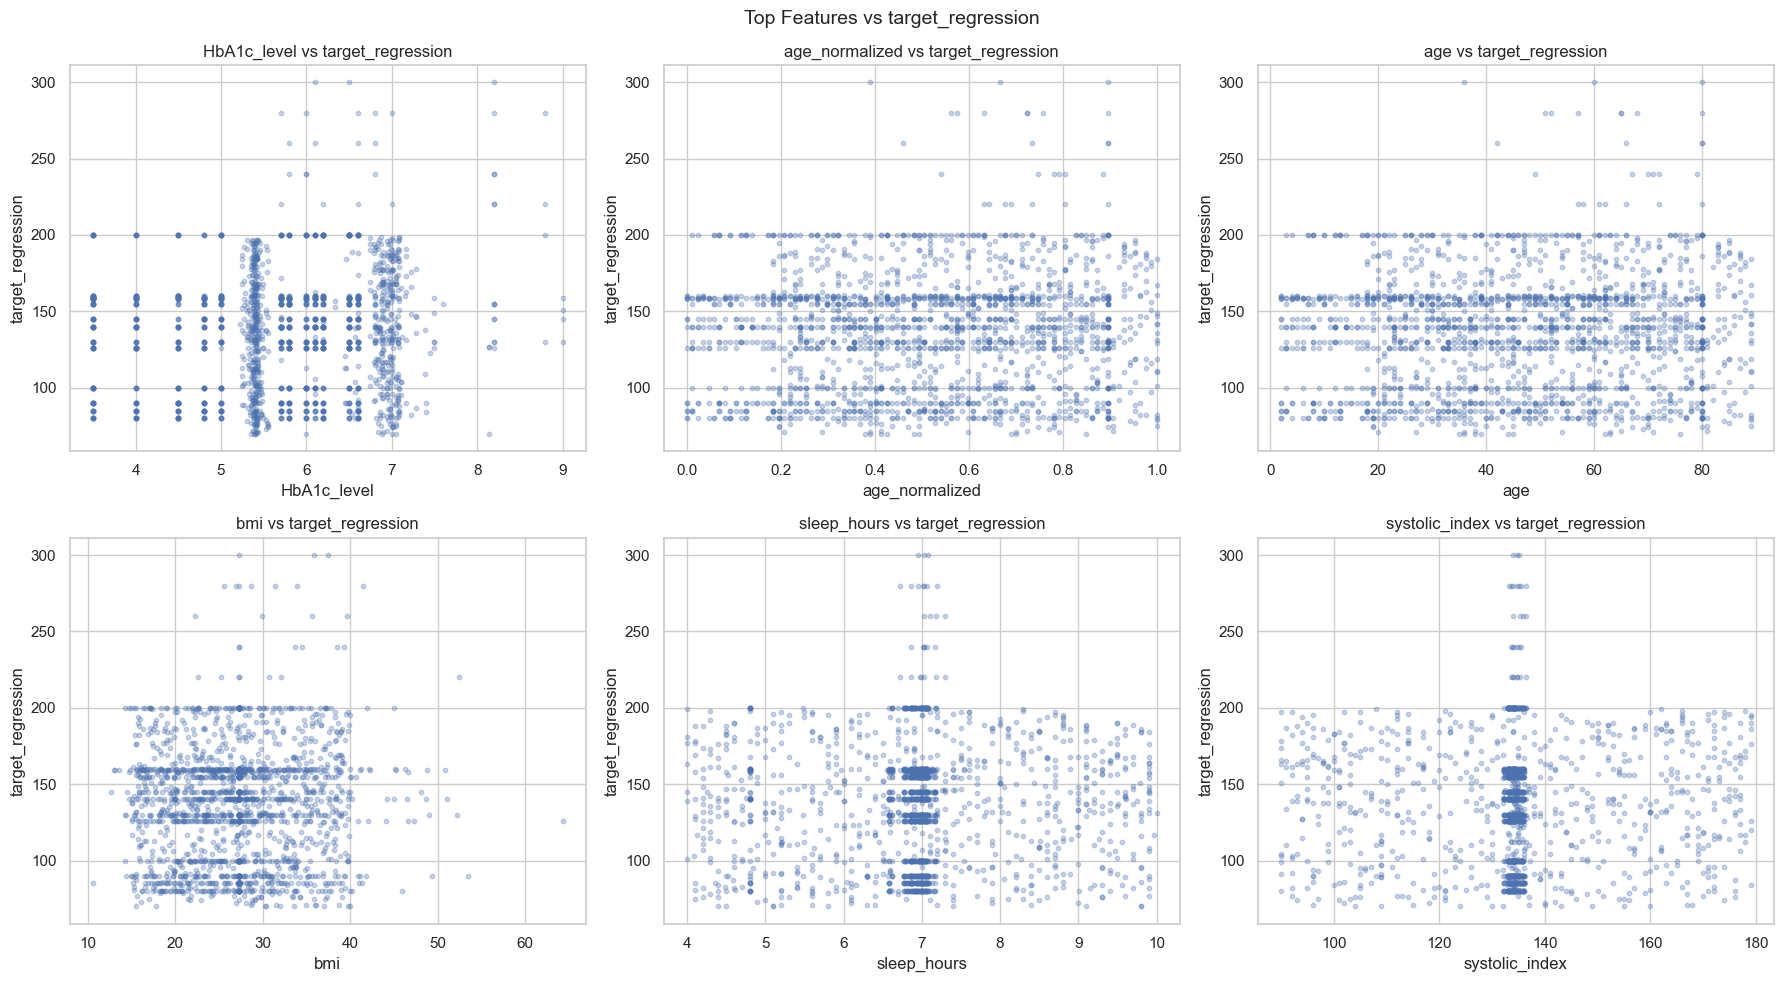

In [22]:
# Scatter: top correlated features vs target_regression
corr_with_target = df[numerical_cols].corr()['target_regression'].drop('target_regression').abs().sort_values(ascending=False)
print('Top correlations with target_regression:')
print(corr_with_target.head(10))

top_features = corr_with_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(top_features):
    axes[i].scatter(df[col], df['target_regression'], alpha=0.3, s=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_regression')
    axes[i].set_title(f'{col} vs target_regression')

plt.suptitle('Top Features vs target_regression', fontsize=14)
plt.tight_layout()
plt.show()

## 6. Conclusions

*(Fill in after analysis)*

- **Uninformative / constant features:**
- **Redundant features:**
- **Key observations:**